# COVID-19 in Europe: case trajectories and government interventions

## 1. Topic and motivation

Between 2020 and 2022 European governments introduced very different non-pharmaceutical
interventions (lockdowns) at very different moments of their epidemics. Some countries (e.g. Italy, Spain) imposed strict national stay-at-home orders in March 2020, whereas Sweden did not introduce a legally binding general stay-at-home order. Finland and Switzerland also avoided a general mandatory stay-at-home order, although both imposed substantial closures and mobility restrictions and, in Switzerland’s case, strongly recommended staying at home.

## 2. Data sources

| Dataset | Content | Granularity | Coverage | Link / licence |
|---|---|---|---|---|
| **Our World in Data (OWID) — COVID-19 compact dataset** | Cases, deaths, excess mortality, tests, hospitalisations, vaccinations, demographic context (population, median age, GDP, hospital beds) | Country × date (but see 4.4: case data is **weekly**) | 2020-01-01 → today, 250+ entities | [catalog.ourworldindata.org](https://catalog.ourworldindata.org/garden/covid/latest/compact/compact.csv), CC BY 4.0 |
| **Oxford COVID-19 Government Response Tracker (OxCGRT)** — national compact file | 20+ policy indicators (C1–C8 containment, E economic, H health, V vaccination), composite indices (Stringency), plus daily confirmed cases/deaths (from JHU) | Country × day | 2020-01-01 → 2022-12-31, 185 countries | [github.com/OxCGRT/covid-policy-dataset](https://github.com/OxCGRT/covid-policy-dataset), CC BY 4.0 |

**Why these two datasets?** They are complementary: OWID describes the *epidemic and its outcomes*,
OxCGRT describes the *policy response*. Both use ISO-3 country codes, so they can be joined on
country × date. Together they give temporal (daily/weekly series), spatial (countries → map) and
multivariate (many policy indicators and country characteristics) data.

## 3. Analytical questions

| # | Question | Data | Main views | Notebook section |
|---|---|---|---|---|
| **Q1** | How did COVID-19 case trajectories change following major government interventions (stay-at-home orders) across European countries? | OxCGRT (C6M stay-at-home, daily cases) | Heatmap of stay-at-home levels, trajectories aligned on Day 0, growth before vs after Day 0 | 4.7, 5.2-5.3, 6.2 |
| **Q2** | Did the *timing* of the intervention matter? Did countries that locked down at a lower case level experience lower excess mortality? | OxCGRT (Day 0) + OWID (excess mortality) | Scatter plot: case level at Day 0 vs first-wave excess mortality | 6.3 |
| **Q3** | Are there distinct European "response strategies" over 2020-2022, and do they follow geography? | OxCGRT (stringency over time) | PCA + k-means of monthly stringency, cluster profiles | 7 |
| **Q4** | Did countries that never imposed a general lockdown (Sweden, Nordics, Switzerland) end up worse off than comparable neighbours? | OxCGRT + OWID | Small multiples of stringency, cases, excess mortality (Sweden vs Norway, Denmark, Finland) | 6.4 |
| **Q5** | How did vaccination change the relationship between restrictions, cases and deaths? | OWID (vaccination) + OxCGRT | Linked monthly time series | 6.5 |
| **Q6** | Do country characteristics (wealth, age structure, health-care capacity, comorbidities, population density) explain the COVID-19 burden better than how strict the policies were? In particular: did richer countries report more cases but suffer fewer deaths? | OWID (GDP per capita, median age, hospital beds, diabetes prevalence, population density, tests) + stringency | Correlation matrix, scatter plots coloured by region | 4.10, 6.6 |
| **Q7** | How reliable are official COVID-19 death counts? Where is the gap between reported COVID-19 deaths and excess mortality largest? | OWID (COVID deaths, excess mortality) | Scatter of reported vs excess deaths with diagonal, excess/reported ratio | 6.7 |

## 4. Data analysis

### 4.1 Loading the data

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

OWID_URL = "https://catalog.ourworldindata.org/garden/covid/latest/compact/compact.csv"
OXCGRT_URL = ("https://raw.githubusercontent.com/OxCGRT/covid-policy-dataset/main/data/OxCGRT_compact_national_v1.csv")

owid = pd.read_csv(OWID_URL, low_memory=False)
policy = pd.read_csv(OXCGRT_URL, low_memory=False)

print("OWID:  ", owid.shape)
print("OxCGRT:", policy.shape)

OWID:   (628125, 61)
OxCGRT: (202760, 56)


### 4.2 First look at the variables

In [8]:
print(owid.columns.tolist())

['country', 'date', 'total_cases', 'new_cases', 'new_cases_smoothed', 'total_cases_per_million', 'new_cases_per_million', 'new_cases_smoothed_per_million', 'total_deaths', 'new_deaths', 'new_deaths_smoothed', 'total_deaths_per_million', 'new_deaths_per_million', 'new_deaths_smoothed_per_million', 'excess_mortality', 'excess_mortality_cumulative', 'excess_mortality_cumulative_absolute', 'excess_mortality_cumulative_per_million', 'hosp_patients', 'hosp_patients_per_million', 'weekly_hosp_admissions', 'weekly_hosp_admissions_per_million', 'icu_patients', 'icu_patients_per_million', 'weekly_icu_admissions', 'weekly_icu_admissions_per_million', 'stringency_index', 'reproduction_rate', 'total_tests', 'new_tests', 'total_tests_per_thousand', 'new_tests_per_thousand', 'new_tests_smoothed', 'new_tests_smoothed_per_thousand', 'positive_rate', 'tests_per_case', 'total_vaccinations', 'people_vaccinated', 'people_fully_vaccinated', 'total_boosters', 'new_vaccinations', 'new_vaccinations_smoothed', 

In [10]:
owid.sample(5, random_state=1)

,country,date,total_cases,new_cases,new_cases_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths,new_deaths,new_deaths_smoothed,total_deaths_per_million,new_deaths_per_million,new_deaths_smoothed_per_million,excess_mortality,excess_mortality_cumulative,excess_mortality_cumulative_absolute,excess_mortality_cumulative_per_million,hosp_patients,hosp_patients_per_million,...,new_vaccinations_smoothed,total_vaccinations_per_hundred,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred,total_boosters_per_hundred,new_vaccinations_smoothed_per_million,new_people_vaccinated_smoothed,new_people_vaccinated_smoothed_per_hundred,code,continent,population,population_density,median_age,life_expectancy,gdp_per_capita,extreme_poverty,diabetes_prevalence,handwashing_facilities,hospital_beds_per_thousand,human_development_index
114454,Colombia,2021-08-11,4843007.0,4023.0,5993.857,93606.4840,77.75725,115.85032,122601.0,143.0,197.85715,2369.653600,2.763929,3.824217,NaN,NaN,NaN,NaN,NaN,NaN,...,305050.8400,60.205894,39.162254,26.101970,NaN,5896.0760,204531.1400,0.395321,COL,South America,5.173794e+07,46.631767,31.181000,76.508102,18778.648438,8.500736,8.4,70.426590,1.70,NaN
324204,Macao,2021-05-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2031.8572,18.869612,12.045545,6.853030,NaN,2884.6855,1035.2858,0.146982,MAC,Asia,7.043600e+05,21344.242188,37.831001,82.102501,117098.273438,NaN,8.1,NaN,NaN,NaN
113561,China,2025-12-11,99381761.0,0.0,0.000,69732.8000,0.00000,0.00000,122398.0,0.0,0.00000,85.882515,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CHN,Asia,1.425180e+09,151.805252,38.534000,78.202103,25066.521484,0.000000,11.9,97.266319,5.63,NaN
422134,Pakistan,2024-11-30,1580631.0,0.0,0.000,6485.9526,0.00000,0.00000,30656.0,0.0,0.00000,125.793660,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PAK,Asia,2.437007e+08,316.133087,20.148001,67.416702,5617.250977,22.956307,31.4,84.766663,0.63,NaN
246037,Hong Kong,2022-01-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,37797.5700,142.926620,69.609314,63.439835,9.877466,5062.6855,15750.1430,0.210961,HKG,Asia,7.465913e+06,7110.393555,45.591000,83.485298,68724.554688,NaN,8.2,NaN,NaN,NaN


In [11]:
print(policy.columns.tolist())

['CountryName', 'CountryCode', 'RegionName', 'RegionCode', 'Jurisdiction', 'Date', 'C1M_School closing', 'C1M_Flag', 'C2M_Workplace closing', 'C2M_Flag', 'C3M_Cancel public events', 'C3M_Flag', 'C4M_Restrictions on gatherings', 'C4M_Flag', 'C5M_Close public transport', 'C5M_Flag', 'C6M_Stay at home requirements', 'C6M_Flag', 'C7M_Restrictions on internal movement', 'C7M_Flag', 'C8EV_International travel controls', 'E1_Income support', 'E1_Flag', 'E2_Debt/contract relief', 'E3_Fiscal measures', 'E4_International support', 'H1_Public information campaigns', 'H1_Flag', 'H2_Testing policy', 'H3_Contact tracing', 'H4_Emergency investment in healthcare', 'H5_Investment in vaccines', 'H6M_Facial Coverings', 'H6M_Flag', 'H7_Vaccination policy', 'H7_Flag', 'H8M_Protection of elderly people', 'H8M_Flag', 'V1_Vaccine Prioritisation (summary)', 'V2A_Vaccine Availability (summary)', 'V2B_Vaccine age eligibility/availability age floor (general population summary)', 'V2C_Vaccine age eligibility/avail

In [12]:
C6 = "C6M_Stay at home requirements"
FLAG = "C6M_Flag"

policy[["CountryName", "CountryCode", "Date", C6, FLAG,
        "StringencyIndex_Average", "ConfirmedCases", "ConfirmedDeaths"]].sample(5, random_state=1)

,CountryName,CountryCode,Date,C6M_Stay at home requirements,C6M_Flag,StringencyIndex_Average,ConfirmedCases,ConfirmedDeaths
141033,Panama,PAN,20220115,0.0,NaN,31.19,567578.0,7511.0
163691,San Marino,SMR,20210122,2.0,1.0,69.44,2833.0,65.0
14201,Benin,BEN,20221115,0.0,NaN,5.56,27922.0,163.0
182511,Tonga,TON,20210729,2.0,1.0,43.52,0.0,0.0
172021,Sweden,SWE,20221111,0.0,NaN,11.11,2618688.0,20857.0


In [13]:
print("OWID date column type:  ", owid["date"].dtype, "-> example:", owid["date"].iloc[0])
print("OxCGRT date column type:", policy["Date"].dtype, "-> example:", policy["Date"].iloc[0])

OWID date column type:   str -> example: 2020-01-01
OxCGRT date column type: int64 -> example: 20200101


The two datasets store dates differently: OWID uses ISO strings (`2020-03-15`), OxCGRT uses an
integer `20200315`. Both must be converted to `datetime` before joining.

In [14]:
owid["date"] = pd.to_datetime(owid["date"])
policy["Date"] = pd.to_datetime(policy["Date"].astype(str), format="%Y%m%d")

print("OWID dates:  ", owid["date"].min().date(), "->", owid["date"].max().date())
print("OxCGRT dates:", policy["Date"].min().date(), "->", policy["Date"].max().date())

OWID dates:   2020-01-01 -> 2026-10-11
OxCGRT dates: 2020-01-01 -> 2022-12-31


**Time coverage.** OWID continues until today, OxCGRT stops at the end of 2022.
Any analysis that combines policies and outcomes must be restricted to **2020–2022**.

### 4.3 European subset

In [15]:
europe = owid[owid["continent"] == "Europe"].copy()

print(europe["country"].nunique(), "European entities in OWID:")
print(sorted(europe["country"].unique()))

52 European entities in OWID:
['Albania', 'Andorra', 'Austria', 'Belarus', 'Belgium', 'Bosnia and Herzegovina', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Estonia', 'Faroe Islands', 'Finland', 'France', 'Germany', 'Gibraltar', 'Greece', 'Guernsey', 'Hungary', 'Iceland', 'Ireland', 'Isle of Man', 'Italy', 'Jersey', 'Kosovo', 'Latvia', 'Liechtenstein', 'Lithuania', 'Luxembourg', 'Malta', 'Moldova', 'Monaco', 'Montenegro', 'Netherlands', 'North Macedonia', 'Norway', 'Poland', 'Portugal', 'Romania', 'Russia', 'San Marino', 'Serbia', 'Slovakia', 'Slovenia', 'Spain', 'Sweden', 'Switzerland', 'Transnistria', 'Ukraine', 'United Kingdom', 'Vatican']


In [16]:
# Entities whose code is not a standard ISO-3 code
europe[europe["code"].str.len() != 3][["country", "code"]].drop_duplicates()

,country,code
289045,Kosovo,OWID_KOS
559712,Transnistria,OWID_TRS


In [17]:
population = europe.groupby("country")["population"].max().sort_values()
population.head(12)

country
Vatican             513.0
San Marino        34113.0
Gibraltar         37631.0
Monaco            38950.0
Liechtenstein     39338.0
Faroe Islands     54039.0
Guernsey          63750.0
Andorra           79722.0
Isle of Man       84148.0
Jersey           103493.0
Iceland          380368.0
Malta            528194.0
Name: population, dtype: float64

OWID's "Europe" includes **microstates and territories** (Vatican, Gibraltar, San Marino,
Monaco, Liechtenstein, Faroe Islands, Channel Islands). With populations below 100,000, a handful
of cases produces extreme per-capita values, so they will be excluded from comparative analyses.
Kosovo uses the non-standard code `OWID_KOS` (OxCGRT uses `RKS`).

### 4.4 Reporting frequency: daily or weekly?

In [18]:
portugal = europe[(europe["country"] == "Portugal")
                  & europe["date"].between("2020-04-01", "2020-04-21")]
portugal[["date", "new_cases", "new_cases_smoothed"]]

,date,new_cases,new_cases_smoothed
445184,2020-04-01,0.0,532.2857
445185,2020-04-02,0.0,532.2857
445186,2020-04-03,0.0,532.2857
445187,2020-04-04,0.0,532.2857
445188,2020-04-05,5045.0,720.7143
445189,2020-04-06,0.0,720.7143
445190,2020-04-07,0.0,720.7143
445191,2020-04-08,0.0,720.7143
445192,2020-04-09,0.0,720.7143
445193,2020-04-10,0.0,720.7143


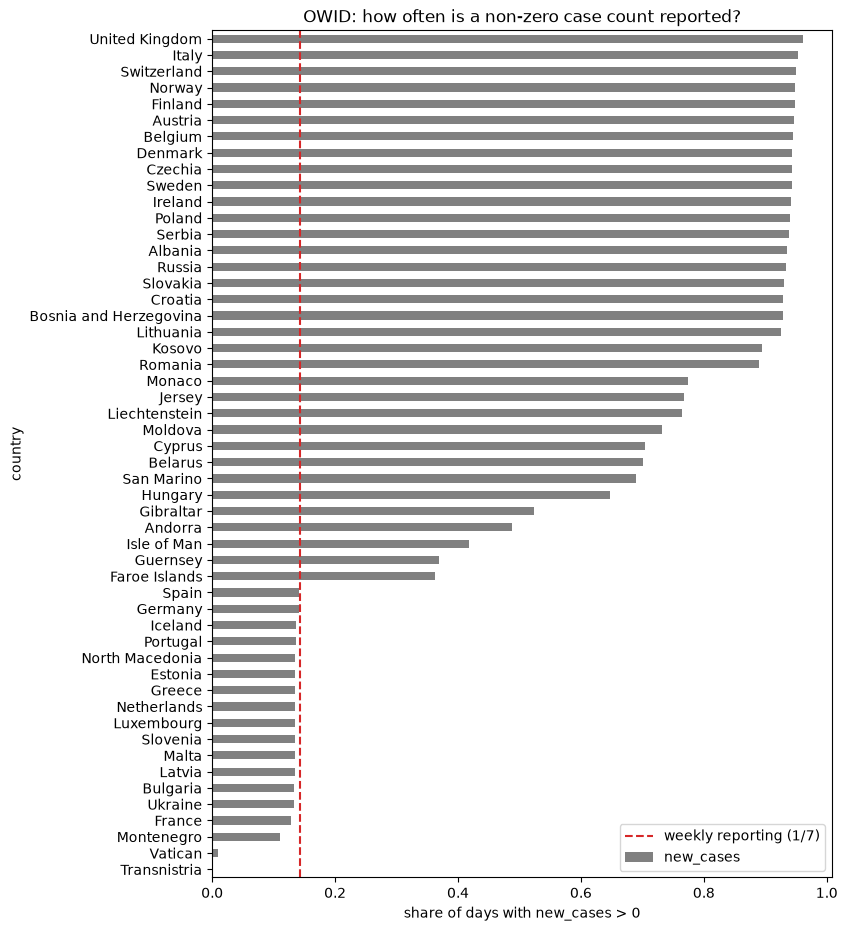

Weekly reporting: ['Transnistria', 'Vatican', 'Montenegro', 'France', 'Ukraine', 'Bulgaria', 'Latvia', 'Malta', 'Slovenia', 'Luxembourg', 'Netherlands', 'Greece', 'Estonia', 'North Macedonia', 'Portugal', 'Iceland', 'Germany', 'Spain']
Daily reporting:  ['Romania', 'Kosovo', 'Lithuania', 'Bosnia and Herzegovina', 'Croatia', 'Slovakia', 'Russia', 'Albania', 'Serbia', 'Poland', 'Ireland', 'Sweden', 'Czechia', 'Denmark', 'Belgium', 'Austria', 'Finland', 'Norway', 'Switzerland', 'Italy', 'United Kingdom']


In [19]:
# Share of days with new_cases > 0 per country (2020-2022).
# Daily reporting -> close to 1.0, weekly reporting -> close to 1/7 = 0.14
cadence = (europe[europe["date"] < "2023-01-01"]
           .groupby("country")["new_cases"]
           .apply(lambda s: (s > 0).mean())
           .sort_values())

cadence.plot.barh(figsize=(8, 11), color="grey")
plt.axvline(1 / 7, color="tab:red", linestyle="--", label="weekly reporting (1/7)")
plt.xlabel("share of days with new_cases > 0")
plt.title("OWID: how often is a non-zero case count reported?")
plt.legend()
plt.show()

print("Weekly reporting:", list(cadence[cadence < 0.2].index))
print("Daily reporting: ", list(cadence[cadence > 0.85].index))

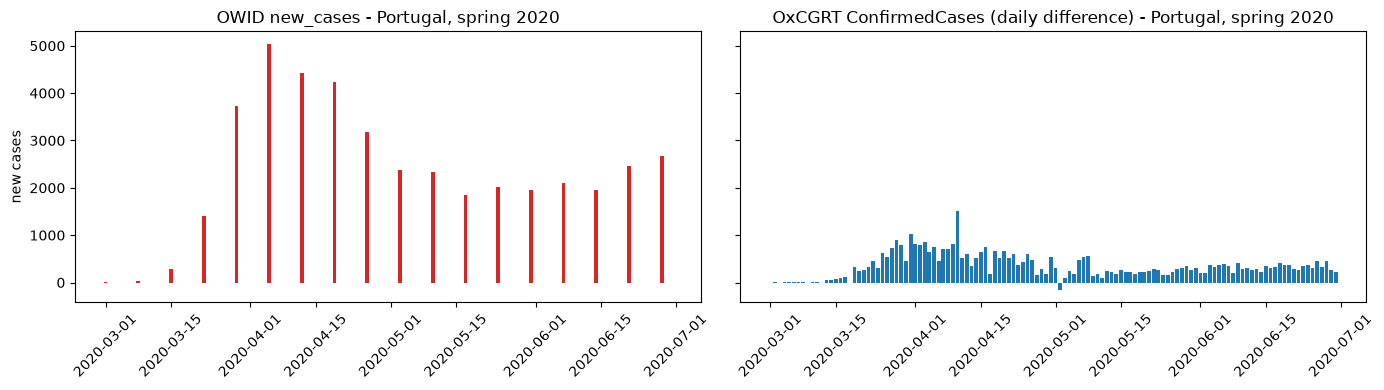

In [20]:
policy = policy.sort_values(["CountryCode", "Date"])
policy["new_cases"] = policy.groupby("CountryCode")["ConfirmedCases"].diff()

pt_owid = europe[(europe["country"] == "Portugal") & europe["date"].between("2020-03-01", "2020-06-30")]
pt_ox = policy[(policy["CountryCode"] == "PRT") & policy["Date"].between("2020-03-01", "2020-06-30")]

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
axes[0].bar(pt_owid["date"], pt_owid["new_cases"], color="tab:red")
axes[0].set_title("OWID new_cases - Portugal, spring 2020")
axes[1].bar(pt_ox["Date"], pt_ox["new_cases"], color="tab:blue")
axes[1].set_title("OxCGRT ConfirmedCases (daily difference) - Portugal, spring 2020")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("new cases")
plt.tight_layout()
plt.show()

**Temporal granularity, even inside OWID.** OWID's case data comes from the WHO and
has no single frequency. For about a third of the countries (France, Germany, Spain, Portugal,
Netherlands, Greece) cases are **weekly**: `new_cases` is 0 on six days and contains the whole
week's total on Sunday, and `new_cases_smoothed` is a step function that stays constant for seven
days. For others (Italy, United Kingdom, Poland, the Nordics) they are **daily**, and a few
countries switch between the two. OxCGRT's `ConfirmedCases` (cumulative, originally from Johns
Hopkins) is **daily for every country**.

Consequences:
* the OWID "new cases" variable cannot be shown day by day (an animated map would flicker between 0 and a weekly spike for a third of the countries);
* countries are not comparable day by day: some curves are smooth, others are staircases;
* aligning countries on a daily Day 0 with weekly data introduces up to +-6 days of error;
* dividing by the value on Day 0 fails whenever Day 0 is not a Sunday (value 0).

**Decision:** for daily analyses around interventions we use daily new cases derived from OxCGRT
(`ConfirmedCases.diff()`), smoothed with a 7-day rolling mean. OWID is used for weekly/cumulative
outcomes (excess mortality, vaccination) and country characteristics.

In [21]:
# Daily differences of a cumulative series can be negative (data corrections)
neg = policy[policy["new_cases"] < 0]
print(len(neg), "negative daily differences, e.g.:")
neg[["CountryName", "Date", "ConfirmedCases", "new_cases"]].head()

160 negative daily differences, e.g.:


,CountryName,Date,ConfirmedCases,new_cases
1022,Aruba,2022-10-19,43291.0,-854.0
1175,Afghanistan,2020-03-20,24.0,-2.0
1829,Afghanistan,2022-01-03,158183.0,-6.0
8433,Australia,2022-01-31,2580386.0,-26856.0
8449,Australia,2022-02-16,2967316.0,-2574.0


### 4.5 Country coverage and naming

In [22]:
owid_codes = set(europe["code"])
ox_codes = set(policy["CountryCode"])

print("European OWID codes missing in OxCGRT:", sorted(owid_codes - ox_codes))

European OWID codes missing in OxCGRT: ['GGY', 'GIB', 'IMN', 'JEY', 'MKD', 'MNE', 'OWID_KOS', 'OWID_TRS', 'VAT']


In [23]:
names = (europe[["code", "country"]].drop_duplicates()
         .merge(policy[["CountryCode", "CountryName"]].drop_duplicates(),
                left_on="code", right_on="CountryCode"))
names[names["country"] != names["CountryName"]]

,code,country,CountryCode,CountryName
9,CZE,Czechia,CZE,Czech Republic
12,FRO,Faroe Islands,FRO,Faeroe Islands
36,SVK,Slovakia,SVK,Slovak Republic


**Country identifiers.** Several countries are named differently
(`Czechia` / `Czech Republic`, `Slovakia` / `Slovak Republic`, `Faroe Islands` / `Faeroe Islands`),
so the datasets must be joined on the **ISO-3 code**, never on the name. North Macedonia,
Montenegro, Vatican and the Channel Islands have no policy data at all.

### 4.6 Missing values (Europe, 2020-2022)

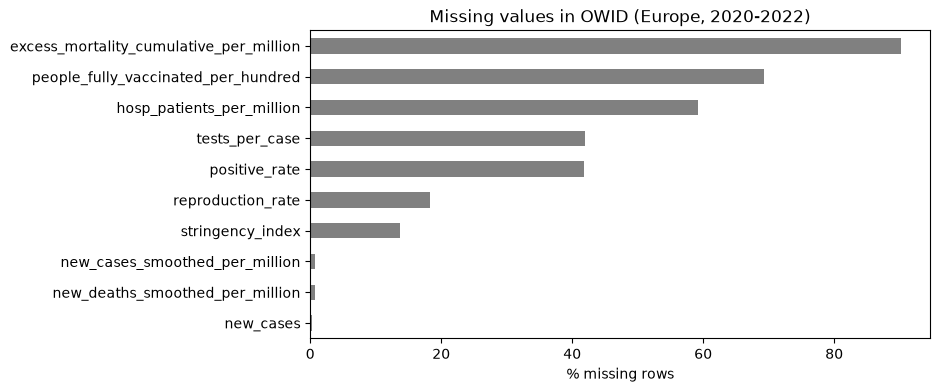

In [24]:
europe_2020_22 = europe[europe["date"] < "2023-01-01"]

key_columns = ["new_cases", "new_cases_smoothed_per_million", "new_deaths_smoothed_per_million",
               "stringency_index", "reproduction_rate", "people_fully_vaccinated_per_hundred",
               "positive_rate", "tests_per_case", "hosp_patients_per_million",
               "excess_mortality_cumulative_per_million"]

missing = europe_2020_22[key_columns].isna().mean().mul(100).sort_values()

missing.plot.barh(figsize=(8, 4), color="grey")
plt.xlabel("% missing rows")
plt.title("Missing values in OWID (Europe, 2020-2022)")
plt.show()

In [25]:
# Excess mortality is published weekly/monthly, so most daily rows are empty.
# What matters is how many countries have it at all:
has_excess = europe_2020_22.groupby("country")["excess_mortality_cumulative_per_million"].count() > 0
print(has_excess.sum(), "of", len(has_excess), "European entities have excess mortality data")

47 of 52 European entities have excess mortality data


Missing values are mostly **structural**, not random: excess mortality is only reported once a week
or month, tests and positive rate were dropped by many countries in 2022, and hospital data is
only available for some countries. These variables must be aggregated to weekly/monthly values
or used for a subset of countries.

### 4.7 The policy variable: stay-at-home requirements (C6M)

| C6M value | Meaning |
|---|---|
| 0 | no measures |
| 1 | recommend not leaving the house |
| 2 | require not leaving the house, with exceptions (exercise, groceries, essential trips) |
| 3 | require not leaving the house, with minimal exceptions |

`C6M_Flag` = 1 means the measure is *general* (whole country), 0 means *targeted* (some regions only).

In [26]:
eu_policy = policy[policy["CountryCode"].isin(owid_codes)].copy()

print(eu_policy[C6].value_counts(dropna=False).sort_index(), "\n")
print(eu_policy[FLAG].value_counts(dropna=False))

C6M_Stay at home requirements
0.0    29573
1.0     9871
2.0     7487
3.0      197
Name: count, dtype: int64 

C6M_Flag
NaN    29573
1.0    14145
0.0     3410
Name: count, dtype: int64


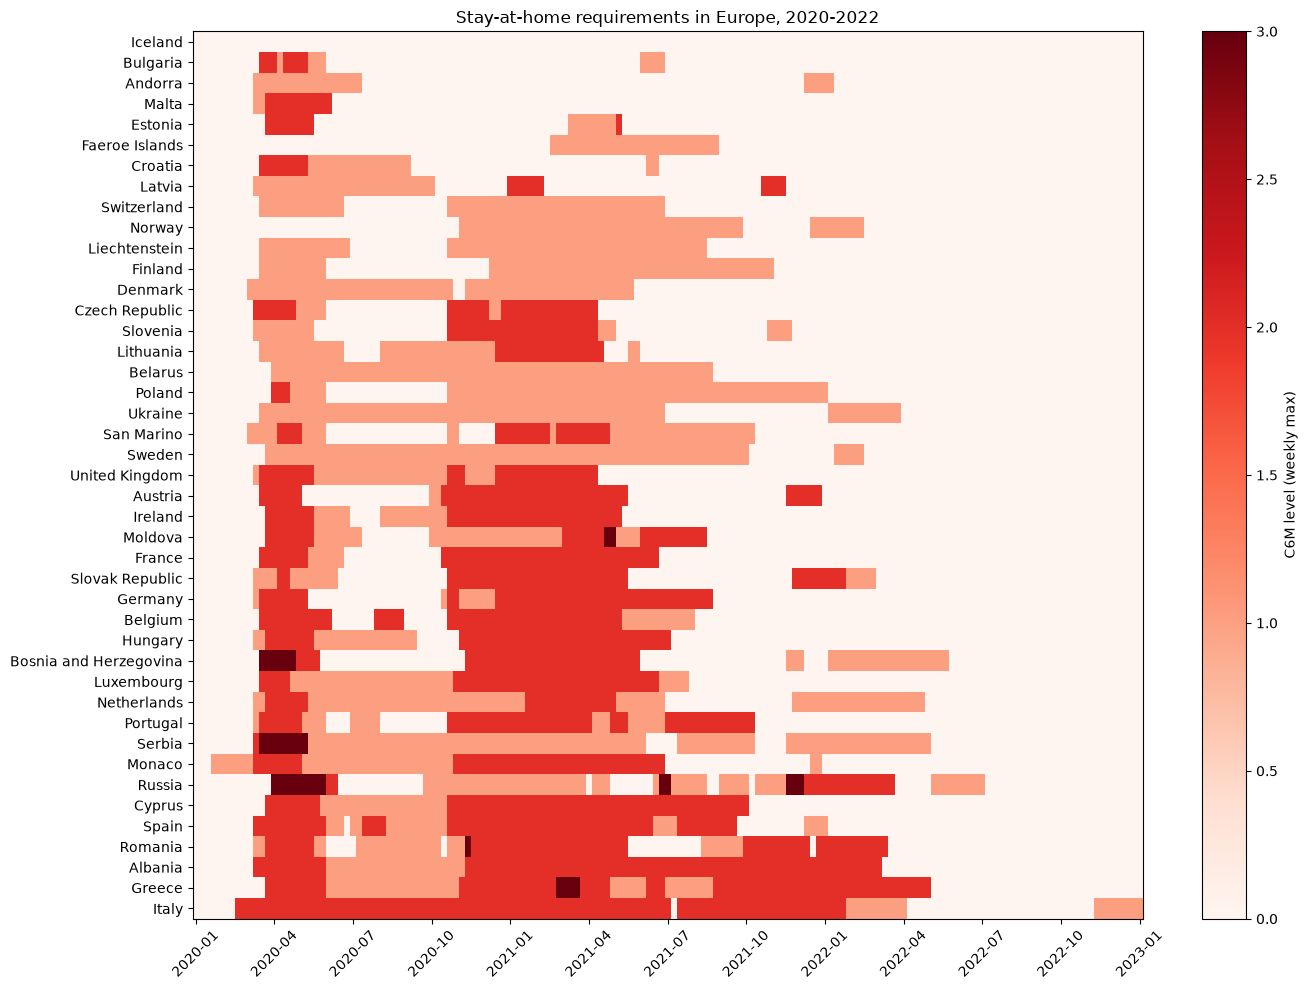

In [27]:
c6_matrix = eu_policy.pivot_table(index="CountryName", columns="Date", values=C6)
c6_weekly = c6_matrix.T.resample("W").max().T
c6_weekly = c6_weekly.loc[c6_weekly.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(14, 10))
im = ax.imshow(c6_weekly, aspect="auto", cmap="Reds", vmin=0, vmax=3)
ax.set_yticks(range(len(c6_weekly)))
ax.set_yticklabels(c6_weekly.index)
month_starts = [i for i, d in enumerate(c6_weekly.columns) if d.day <= 7 and d.month in (1, 4, 7, 10)]
ax.set_xticks(month_starts)
ax.set_xticklabels([c6_weekly.columns[i].strftime("%Y-%m") for i in month_starts], rotation=45)
plt.colorbar(im, label="C6M level (weekly max)")
ax.set_title("Stay-at-home requirements in Europe, 2020-2022")
plt.tight_layout()
plt.show()

The heatmap shows that lockdowns were **not a single event**: most countries had a first lockdown
in March–April 2020 and one or more further periods in autumn 2020 - spring 2021. Several
countries (bottom rows) never reached level 2 or 3.

### 4.8 Distributions

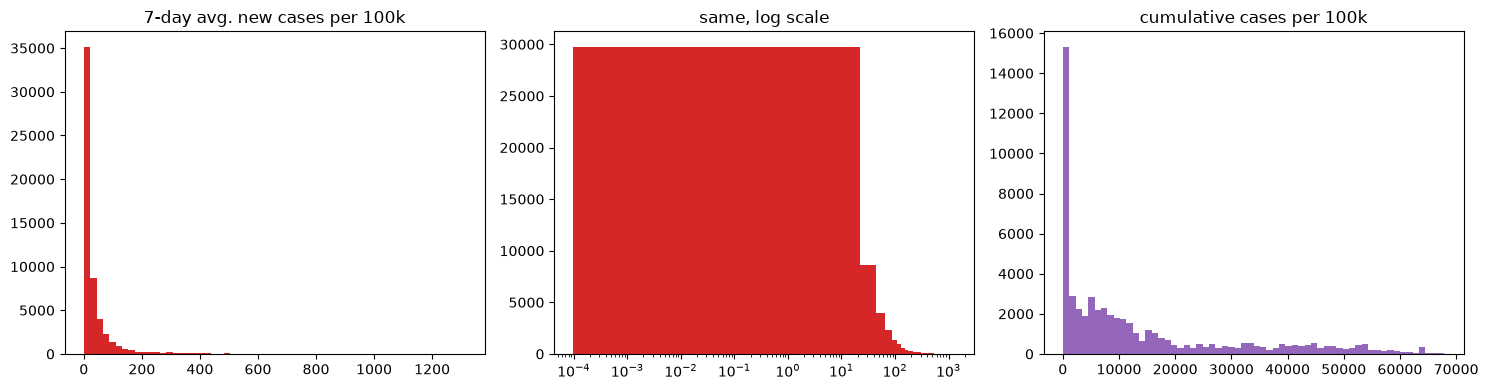

count    55487.0
mean        35.5
std         74.3
min          0.0
25%          1.7
50%         11.3
75%         36.5
max       1314.7
Name: new_cases_smoothed_per_million, dtype: float64
max cumulative cases per 100k: 67918


In [28]:
cases_100k = europe_2020_22["new_cases_smoothed_per_million"].dropna() / 10
cumulative_100k = europe_2020_22["total_cases_per_million"].dropna() / 10

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(cases_100k, bins=60, color="tab:red")
axes[0].set_title("7-day avg. new cases per 100k")
axes[1].hist(cases_100k[cases_100k > 0], bins=60, color="tab:red")
axes[1].set_xscale("log")
axes[1].set_title("same, log scale")
axes[2].hist(cumulative_100k, bins=60, color="tab:purple")
axes[2].set_title("cumulative cases per 100k")
plt.tight_layout()
plt.show()

print(cases_100k.describe().round(1))
print("max cumulative cases per 100k:", round(cumulative_100k.max()))

Case rates are **strongly right-skewed** and span several orders of magnitude (from <1 to >1,000
per 100k): a linear colour scale hides almost all variation in 2020, so log scales or relative
measures are needed. Cumulative cases reach tens of thousands per 100k, so a single fixed colour
scale cannot work for both daily and cumulative measures.

### 4.9 Summary of data issues

| # | Issue | Consequence | Decision |
|---|---|---|---|
| 1 | OWID until 2026, OxCGRT until 2022 | Policies unknown after 2022 | Restrict joint analysis to 2020–2022 |
| 2 | OWID cases weekly for ~1/3 of the countries, daily for most others; OxCGRT daily for all | Daily alignment on Day 0 impossible with OWID | Daily cases from OxCGRT, 7-day rolling mean |
| 3 | Different date formats | Join fails | Convert both to `datetime` |
| 4 | Different country names, non-ISO codes (`OWID_KOS`) | Join on names loses countries | Join on ISO-3 code |
| 5 | Microstates / territories in "Europe" | Extreme per-capita values | Exclude population < 200k |
| 6 | Negative daily differences | Negative "new cases" | Clip to 0 |
| 7 | Structural missing values (excess mortality, tests) | Gaps in daily series | Use last available value / weekly aggregates |
| 8 | Several lockdown episodes per country | "First lockdown" mixes different waves | Detect all episodes, analyse by wave |
| 9 | Skewed distributions | Linear scales hide variation | Log scales, growth rates |
| 10 | Reported cases ≠ infections (testing changed a lot) | Early-2020 rises partly reflect testing | Discuss as limitation, compare with deaths/excess mortality |

### 4.10 Country characteristics (context variables)
OWID also contains country-level indicators such as population density, median age, GDP per capita,
hospital beds, diabetes prevalence or access to handwashing facilities. Are they usable for Europe?

In [ ]:
context_all = ["population_density", "median_age", "life_expectancy", "gdp_per_capita",
               "extreme_poverty", "diabetes_prevalence", "handwashing_facilities",
               "hospital_beds_per_thousand", "human_development_index"]

europe_big = europe[europe["population"] >= 200_000]

# Do these values change over time? (max number of distinct values per country)
print(europe_big.groupby("country")[context_all].nunique().max().to_dict(), "\n")

# How many of the European countries have a value?
europe_big.groupby("country")[context_all].last().notna().sum().sort_values()

{'population_density': 1, 'median_age': 1, 'life_expectancy': 1, 'gdp_per_capita': 1, 'extreme_poverty': 1, 'diabetes_prevalence': 1, 'handwashing_facilities': 1, 'hospital_beds_per_thousand': 1, 'human_development_index': 0} 



human_development_index        0
handwashing_facilities         6
hospital_beds_per_thousand    40
population_density            40
gdp_per_capita                41
life_expectancy               41
diabetes_prevalence           41
median_age                    41
extreme_poverty               41
dtype: int64

**Context variables are static and partly empty for Europe.** Each indicator has a single value
per country (one reference year), so it can only be used for *between-country* comparisons, not
over time. `handwashing_facilities` exists for only 6 European countries (it is collected for low-
and middle-income countries) and `human_development_index` is empty in the compact dataset, so
both are dropped. GDP per capita, median age, hospital beds, diabetes prevalence and population
density are complete enough to be used in Q6.

## 5. Data preparation

### 5.1 Daily case series per 100k (from OxCGRT)

In [29]:
iso_population = europe.groupby("code")["population"].max()
big_enough = iso_population[iso_population >= 200_000].index

eu = eu_policy[eu_policy["CountryCode"].isin(big_enough)].copy()
eu = eu[["CountryName", "CountryCode", "Date", C6, FLAG,
         "StringencyIndex_Average", "ConfirmedCases", "ConfirmedDeaths"]]

eu["new_cases"] = eu.groupby("CountryCode")["ConfirmedCases"].diff().clip(lower=0)
eu["new_deaths"] = eu.groupby("CountryCode")["ConfirmedDeaths"].diff().clip(lower=0)
eu["cases_7d"] = eu.groupby("CountryCode")["new_cases"].transform(lambda s: s.rolling(7).mean())
eu["cases_7d_per_100k"] = eu["cases_7d"] / eu["CountryCode"].map(iso_population) * 100_000

print(eu["CountryCode"].nunique(), "countries kept")
eu[eu["CountryCode"] == "PRT"].iloc[75:85]

38 countries kept


,CountryName,CountryCode,Date,C6M_Stay at home requirements,C6M_Flag,StringencyIndex_Average,ConfirmedCases,ConfirmedDeaths,new_cases,new_deaths,cases_7d,cases_7d_per_100k
146939,Portugal,PRT,2020-03-16,1.0,1.0,55.56,331.0,0.0,86.0,0.0,43.000000,0.412784
146940,Portugal,PRT,2020-03-17,1.0,1.0,55.56,448.0,1.0,117.0,1.0,58.142857,0.558150
146941,Portugal,PRT,2020-03-18,1.0,1.0,61.11,448.0,2.0,0.0,1.0,55.571429,0.533465
146942,Portugal,PRT,2020-03-19,2.0,1.0,82.41,785.0,3.0,337.0,1.0,103.714286,0.995618
146943,Portugal,PRT,2020-03-20,2.0,1.0,82.41,1020.0,6.0,235.0,3.0,129.714286,1.245208
146944,Portugal,PRT,2020-03-21,2.0,1.0,82.41,1280.0,12.0,260.0,6.0,158.714286,1.523598
146945,Portugal,PRT,2020-03-22,2.0,1.0,82.41,1600.0,14.0,320.0,2.0,193.571429,1.858213
146946,Portugal,PRT,2020-03-23,2.0,1.0,82.41,2060.0,23.0,460.0,9.0,247.000000,2.371107
146947,Portugal,PRT,2020-03-24,2.0,1.0,82.41,2362.0,33.0,302.0,10.0,273.428571,2.624812
146948,Portugal,PRT,2020-03-25,2.0,1.0,82.41,2995.0,43.0,633.0,10.0,363.857143,3.492892


Sanity check: our daily series should match OWID's weekly series in level.

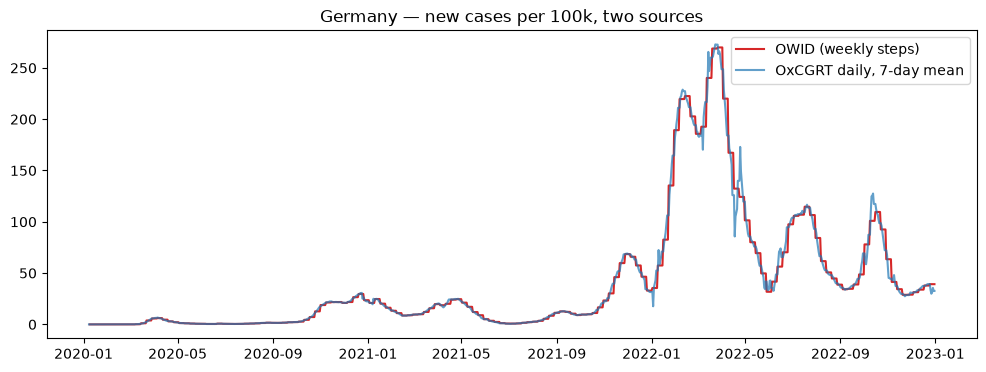

In [30]:
de_ours = eu[eu["CountryCode"] == "DEU"].set_index("Date")["cases_7d_per_100k"]
de_owid = europe[europe["code"] == "DEU"].set_index("date")["new_cases_smoothed_per_million"] / 10

plt.figure(figsize=(12, 4))
plt.plot(de_owid["2020":"2022"], label="OWID (weekly steps)", color="tab:red")
plt.plot(de_ours, label="OxCGRT daily, 7-day mean", color="tab:blue", alpha=0.7)
plt.title("Germany — new cases per 100k, two sources")
plt.legend()
plt.show()

### 5.2 Detecting lockdown episodes
A day counts as **lockdown** when `C6M ≥ 2` and `C6M_Flag = 1` (general stay-at-home order with
at most essential exceptions). An episode starts on the first lockdown day after a non-lockdown day.

In [31]:
eu["lockdown"] = (eu[C6] >= 2) & (eu[FLAG] == 1)
previous_day = eu.groupby("CountryCode")["lockdown"].shift(fill_value=False)
eu["lockdown_start"] = eu["lockdown"] & ~previous_day

starts = eu[eu["lockdown_start"]][["CountryName", "CountryCode", "Date"]]
starts["CountryName"].value_counts()

CountryName
Latvia                    7
Greece                    4
Portugal                  4
Romania                   4
Austria                   3
Cyprus                    3
Czech Republic            3
France                    3
Ireland                   3
Slovak Republic           3
Albania                   2
Belgium                   2
Bosnia and Herzegovina    2
Spain                     2
United Kingdom            2
Hungary                   2
Italy                     2
Luxembourg                2
Netherlands               2
Germany                   1
Estonia                   1
Croatia                   1
Lithuania                 1
Moldova                   1
Malta                     1
Poland                    1
Serbia                    1
Slovenia                  1
Name: count, dtype: int64

In [32]:
def wave(date):
    if date < pd.Timestamp("2020-07-01"):
        return "Wave 1 (spring 2020)"
    if date < pd.Timestamp("2021-04-01"):
        return "Wave 2 (autumn/winter 2020-21)"
    return "Later"

starts["wave"] = starts["Date"].apply(wave)

day0 = (starts[starts["wave"] != "Later"]
        .groupby(["CountryCode", "wave"], as_index=False).first())

day0.pivot(index="CountryName", columns="wave", values="Date").sort_values("Wave 1 (spring 2020)")

wave,Wave 1 (spring 2020),Wave 2 (autumn/winter 2020-21)
CountryName,,
Italy,2020-03-10,2020-10-14
Albania,2020-03-13,2020-11-12
Spain,2020-03-14,2020-10-25
Serbia,2020-03-15,NaT
Czech Republic,2020-03-15,2020-10-22
Austria,2020-03-16,2020-11-02
Luxembourg,2020-03-17,2020-10-30
France,2020-03-17,2020-10-30
Belgium,2020-03-18,2020-10-19


In [33]:
no_lockdown = sorted(set(eu["CountryName"]) - set(starts["CountryName"]))
print("Countries without any general stay-at-home order:", no_lockdown)

Countries without any general stay-at-home order: ['Belarus', 'Bulgaria', 'Denmark', 'Finland', 'Iceland', 'Norway', 'Russia', 'Sweden', 'Switzerland', 'Ukraine']


### 5.3 Relative time ("days since Day 0")
Each country's series is re-indexed relative to the start of its first lockdown in each wave,
so that countries can be compared at the same stage of their intervention.

In [34]:
aligned = eu.merge(day0[["CountryCode", "wave", "Date"]].rename(columns={"Date": "day0"}),
                   on="CountryCode")
aligned["days_from_day0"] = (aligned["Date"] - aligned["day0"]).dt.days
aligned = aligned[aligned["days_from_day0"].between(-30, 90)]

aligned[["CountryName", "wave", "Date", "days_from_day0", "cases_7d_per_100k"]].head()

,CountryName,wave,Date,days_from_day0,cases_7d_per_100k
84,Albania,Wave 1 (spring 2020),2020-02-12,-30,0.0
86,Albania,Wave 1 (spring 2020),2020-02-13,-29,0.0
88,Albania,Wave 1 (spring 2020),2020-02-14,-28,0.0
90,Albania,Wave 1 (spring 2020),2020-02-15,-27,0.0
92,Albania,Wave 1 (spring 2020),2020-02-16,-26,0.0


## 6. Exploratory visual analysis

### 6.1 Overview: Europe 2020-2022

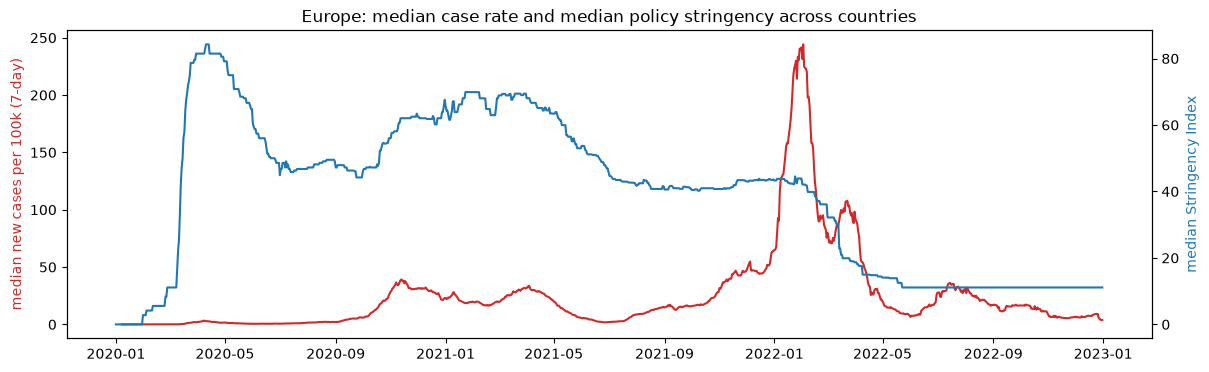

In [35]:
median_by_day = eu.groupby("Date")[["cases_7d_per_100k", "StringencyIndex_Average"]].median()

fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.plot(median_by_day.index, median_by_day["cases_7d_per_100k"], color="tab:red")
ax1.set_ylabel("median new cases per 100k (7-day)", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(median_by_day.index, median_by_day["StringencyIndex_Average"], color="tab:blue")
ax2.set_ylabel("median Stringency Index", color="tab:blue")
plt.title("Europe: median case rate and median policy stringency across countries")
plt.show()

### 6.2 Q1: case trajectories aligned on the lockdown start

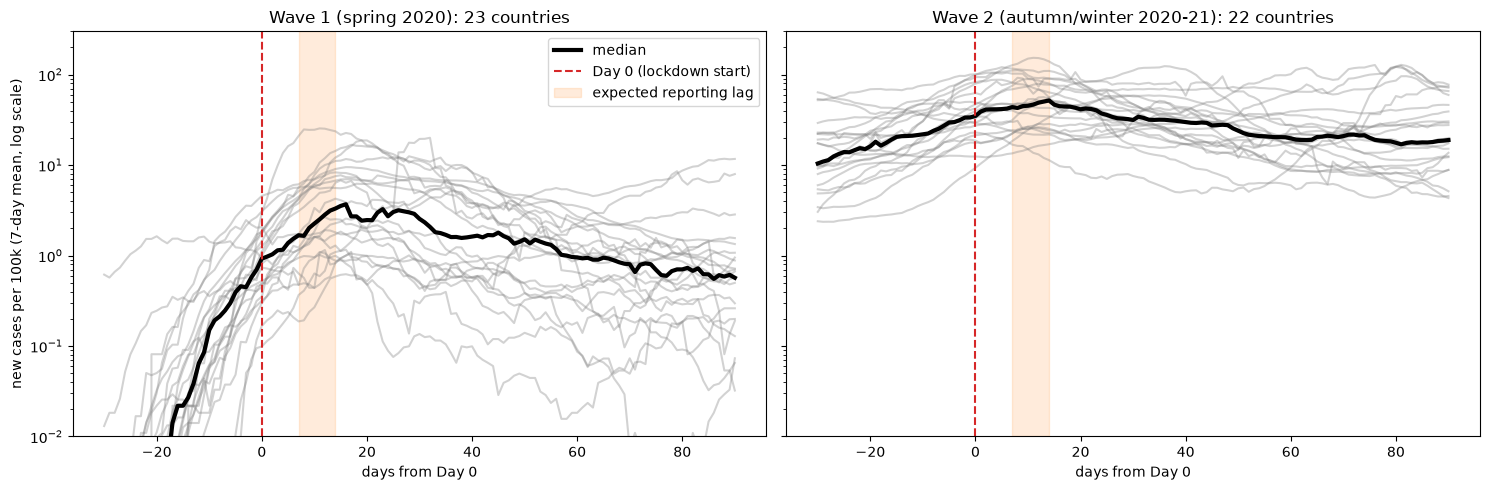

In [36]:
waves = ["Wave 1 (spring 2020)", "Wave 2 (autumn/winter 2020-21)"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, w in zip(axes, waves):
    data = aligned[aligned["wave"] == w]
    for country, g in data.groupby("CountryName"):
        ax.plot(g["days_from_day0"], g["cases_7d_per_100k"], color="grey", alpha=0.35)
    median = data.groupby("days_from_day0")["cases_7d_per_100k"].median()
    ax.plot(median.index, median.values, color="black", linewidth=3, label="median")
    ax.axvline(0, color="tab:red", linestyle="--", label="Day 0 (lockdown start)")
    ax.axvspan(7, 14, color="tab:orange", alpha=0.15, label="expected reporting lag")
    ax.set_yscale("log")
    ax.set_ylim(0.01, 300)
    ax.set_title(f"{w}: {data['CountryName'].nunique()} countries")
    ax.set_xlabel("days from Day 0")
axes[0].set_ylabel("new cases per 100k (7-day mean, log scale)")
axes[0].legend()
plt.tight_layout()
plt.show()

In [37]:
def cases_on(day):
    rows = aligned[aligned["days_from_day0"] == day]
    return rows.set_index(["CountryName", "wave"])["cases_7d"].where(lambda s: s > 0)

growth = pd.DataFrame({
    "weekly growth before (day -7 -> 0)": cases_on(0) / cases_on(-7),
    "weekly growth after (day +14 -> +21)": cases_on(21) / cases_on(14),
}).dropna().reset_index()

growth.groupby("wave")[["weekly growth before (day -7 -> 0)",
                        "weekly growth after (day +14 -> +21)"]].median().round(2)

,weekly growth before (day -7 -> 0),weekly growth after (day +14 -> +21)
wave,,
Wave 1 (spring 2020),3.38,0.97
Wave 2 (autumn/winter 2020-21),1.44,0.87


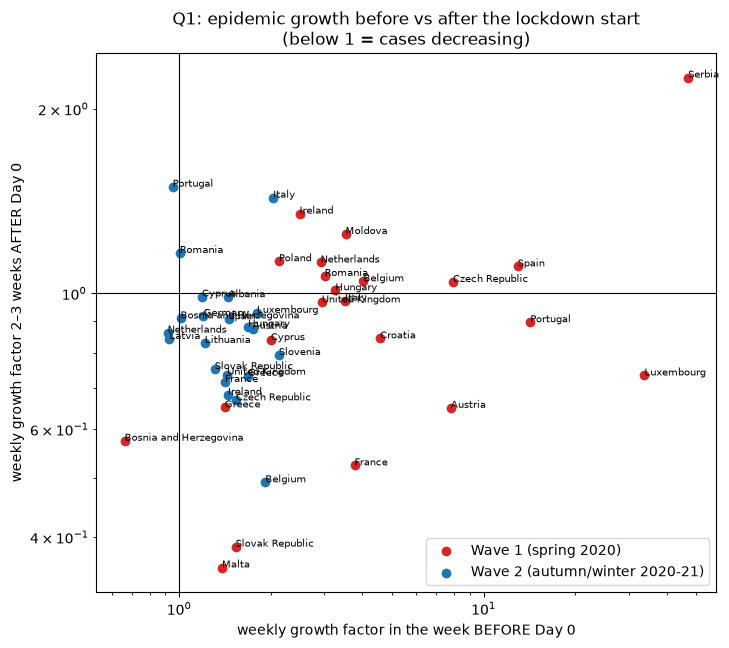

In [38]:
fig, ax = plt.subplots(figsize=(8, 7))
colors = {"Wave 1 (spring 2020)": "tab:red", "Wave 2 (autumn/winter 2020-21)": "tab:blue"}
for w, g in growth.groupby("wave"):
    ax.scatter(g["weekly growth before (day -7 -> 0)"], g["weekly growth after (day +14 -> +21)"],
               color=colors[w], label=w)
    for _, r in g.iterrows():
        ax.annotate(r["CountryName"], (r["weekly growth before (day -7 -> 0)"],
                                       r["weekly growth after (day +14 -> +21)"]), fontsize=7)
ax.axhline(1, color="black", linewidth=0.8)
ax.axvline(1, color="black", linewidth=0.8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("weekly growth factor in the week BEFORE Day 0")
ax.set_ylabel("weekly growth factor 2–3 weeks AFTER Day 0")
ax.set_title("Q1: epidemic growth before vs after the lockdown start\n(below 1 = cases decreasing)")
ax.legend()
plt.show()

### 6.3 Q2: timing of the first lockdown vs excess mortality

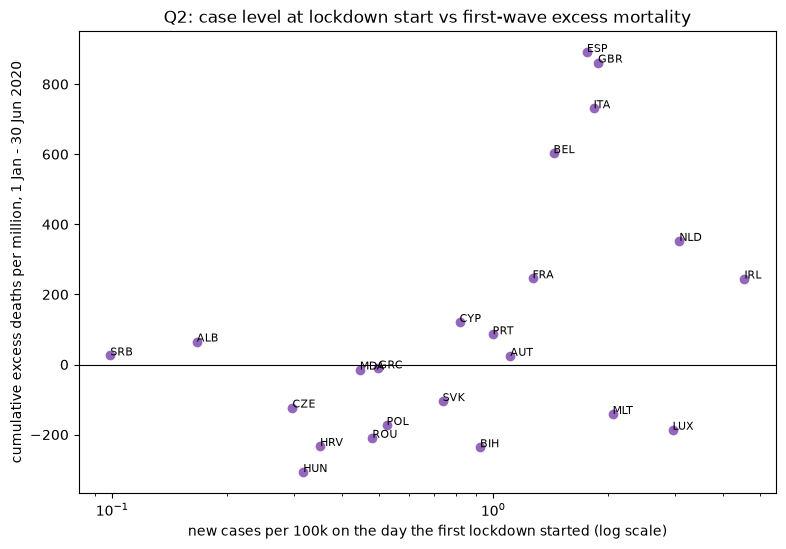

Spearman correlation: 0.48 | n = 23


In [39]:
wave1 = aligned[(aligned["wave"] == "Wave 1 (spring 2020)") & (aligned["days_from_day0"] == 0)]
level_at_day0 = wave1.set_index("CountryCode")["cases_7d_per_100k"]

excess_mid2020 = (europe[europe["date"] <= "2020-06-30"]
                  .dropna(subset=["excess_mortality_cumulative_per_million"])
                  .groupby("code")["excess_mortality_cumulative_per_million"].last())

q2 = pd.DataFrame({"cases_at_day0": level_at_day0, "excess_mortality": excess_mid2020}).dropna()
q2 = q2[q2["cases_at_day0"] > 0]

plt.figure(figsize=(9, 6))
plt.scatter(q2["cases_at_day0"], q2["excess_mortality"], color="tab:purple")
for code_, r in q2.iterrows():
    plt.annotate(code_, (r["cases_at_day0"], r["excess_mortality"]), fontsize=8)
plt.xscale("log")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("new cases per 100k on the day the first lockdown started (log scale)")
plt.ylabel("cumulative excess deaths per million, 1 Jan - 30 Jun 2020")
plt.title("Q2: case level at lockdown start vs first-wave excess mortality")
plt.show()

print("Spearman correlation:", round(q2.corr(method="spearman").iloc[0, 1], 2), "| n =", len(q2))

### 6.4 Q4: Sweden vs its Nordic neighbours

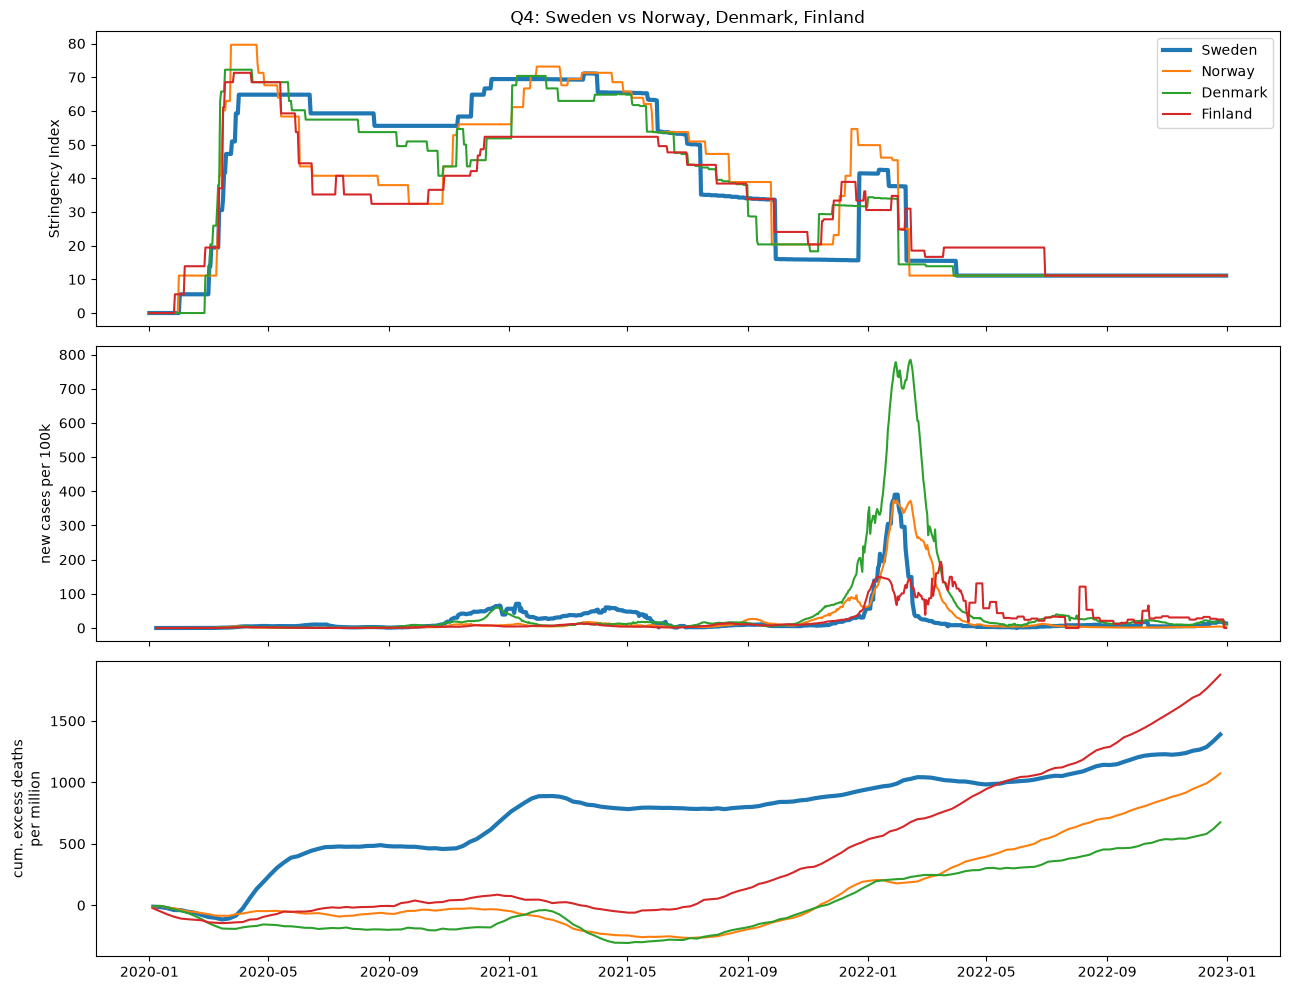

In [40]:
nordics = {"SWE": "Sweden", "NOR": "Norway", "DNK": "Denmark", "FIN": "Finland"}

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for iso, name in nordics.items():
    pol = eu[eu["CountryCode"] == iso]
    out = europe[(europe["code"] == iso) & (europe["date"] < "2023-01-01")]
    out = out.dropna(subset=["excess_mortality_cumulative_per_million"])
    width = 3 if iso == "SWE" else 1.5
    axes[0].plot(pol["Date"], pol["StringencyIndex_Average"], label=name, linewidth=width)
    axes[1].plot(pol["Date"], pol["cases_7d_per_100k"], label=name, linewidth=width)
    axes[2].plot(out["date"], out["excess_mortality_cumulative_per_million"], label=name, linewidth=width)

axes[0].set_ylabel("Stringency Index")
axes[1].set_ylabel("new cases per 100k")
axes[2].set_ylabel("cum. excess deaths\nper million")
axes[0].legend()
axes[0].set_title("Q4: Sweden vs Norway, Denmark, Finland")
plt.tight_layout()
plt.show()

### 6.5 Q5: restrictions, vaccination and deaths per case

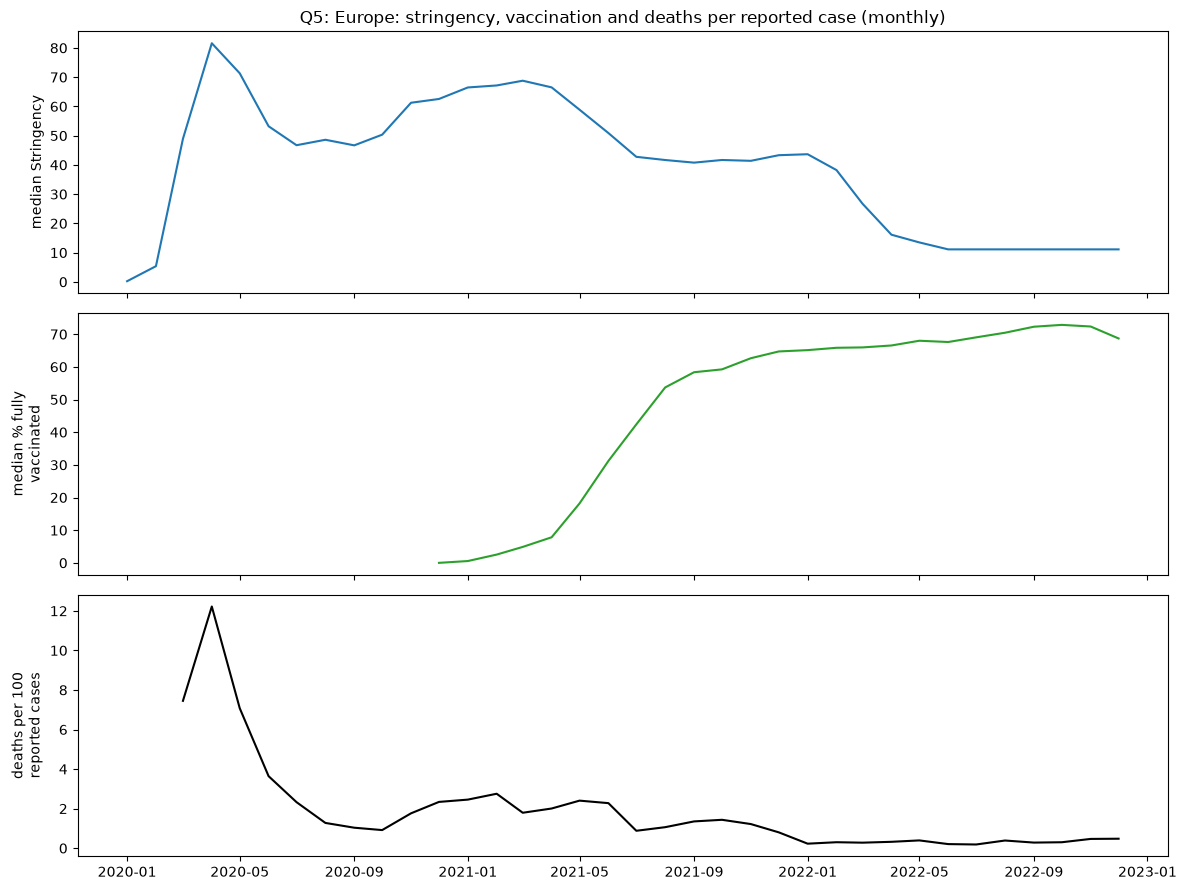

In [42]:
monthly = eu.set_index("Date").groupby(pd.Grouper(freq="MS"))[["new_cases", "new_deaths"]].sum()
monthly["deaths_per_100_cases"] = monthly["new_deaths"] / monthly["new_cases"] * 100

stringency_monthly = (eu.set_index("Date").groupby("CountryCode")["StringencyIndex_Average"]
                      .resample("MS").mean().groupby("Date").median())

vaccinated_monthly = (europe[europe["code"].isin(big_enough)].set_index("date")
                      .groupby("code")["people_fully_vaccinated_per_hundred"]
                      .resample("MS").max().groupby("date").median())["2020":"2022"]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(stringency_monthly, color="tab:blue")
axes[0].set_ylabel("median Stringency")
axes[1].plot(vaccinated_monthly, color="tab:green")
axes[1].set_ylabel("median % fully\nvaccinated")
axes[2].plot(monthly["deaths_per_100_cases"]["2020-03":], color="black")
axes[2].set_ylabel("deaths per 100\nreported cases")
axes[0].set_title("Q5: Europe: stringency, vaccination and deaths per reported case (monthly)")
plt.tight_layout()
plt.show()

### 6.6 Q6: do country characteristics explain the COVID-19 burden?

**Question:** do country characteristics (wealth, age structure, health-care capacity,
comorbidities, population density) explain the COVID-19 burden better than how strict the
policies were? In particular: did richer countries report more cases but suffer fewer deaths?

One row per country with its characteristics (section 4.10) and its cumulative outcomes at the
end of 2022. Countries are coloured by a simple region split: Western Europe vs Central & Eastern
Europe (former communist countries), because many characteristics differ systematically between
the two.

In [ ]:
EXCESS = "excess_mortality_cumulative_per_million"
CENTRAL_EASTERN = ["ALB", "BIH", "BGR", "BLR", "HRV", "CZE", "EST", "HUN", "LVA", "LTU", "MDA",
                   "MNE", "MKD", "POL", "ROU", "RUS", "SRB", "SVK", "SVN", "UKR", "OWID_KOS"]

context_vars = ["gdp_per_capita", "median_age", "hospital_beds_per_thousand",
                "diabetes_prevalence", "population_density"]

until_2022 = europe_big[europe_big["date"] <= "2022-12-31"]
by_country = until_2022.groupby("country")

q6 = by_country[context_vars].last()
q6["cases per million"] = by_country["total_cases_per_million"].max()
q6["COVID deaths per million"] = by_country["total_deaths_per_million"].max()
q6["excess deaths per million"] = until_2022.dropna(subset=[EXCESS]).groupby("country")[EXCESS].last()
q6["tests per thousand"] = by_country["total_tests_per_thousand"].max()
q6["mean stringency"] = by_country["stringency_index"].mean()
q6["region"] = by_country["code"].first().isin(CENTRAL_EASTERN).map(
    {True: "Central & Eastern", False: "Western"})

print(len(q6), "countries")
q6.round(1).head()

41 countries


,gdp_per_capita,median_age,hospital_beds_per_thousand,diabetes_prevalence,population_density,cases per million,COVID deaths per million,excess deaths per million,tests per thousand,mean stringency,region
country,,,,,,,,,,,
Albania,22724.3,35.9,2.9,10.6,103.2,117685.1,1271.7,5970.3,565.3,41.8,Central & Eastern
Austria,63970.4,42.8,6.7,5.4,109.8,628907.8,2386.6,2530.8,21272.1,49.1,Western
Belarus,29666.2,40.2,9.8,5.1,45.2,108362.7,776.0,9591.9,1380.3,23.4,Central & Eastern
Belgium,63488.4,41.2,5.4,5.9,384.5,402420.4,2862.0,2334.5,2955.3,39.0,Western
Bosnia and Herzegovina,21178.2,44.6,2.3,10.3,62.6,125153.8,5065.5,7126.3,458.4,38.7,Central & Eastern


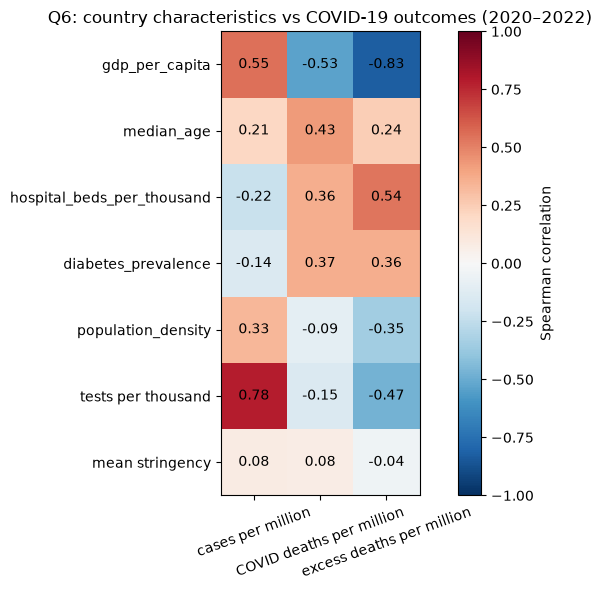

In [ ]:
outcomes = ["cases per million", "COVID deaths per million", "excess deaths per million"]
factors = context_vars + ["tests per thousand", "mean stringency"]

corr = q6[factors + outcomes].corr(method="spearman").loc[factors, outcomes]

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(outcomes)))
ax.set_xticklabels(outcomes, rotation=20)
ax.set_yticks(range(len(factors)))
ax.set_yticklabels(factors)
for i in range(len(factors)):
    for j in range(len(outcomes)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im, label="Spearman correlation")
ax.set_title("Q6: country characteristics vs COVID-19 outcomes (2020–2022)")
plt.tight_layout()
plt.show()

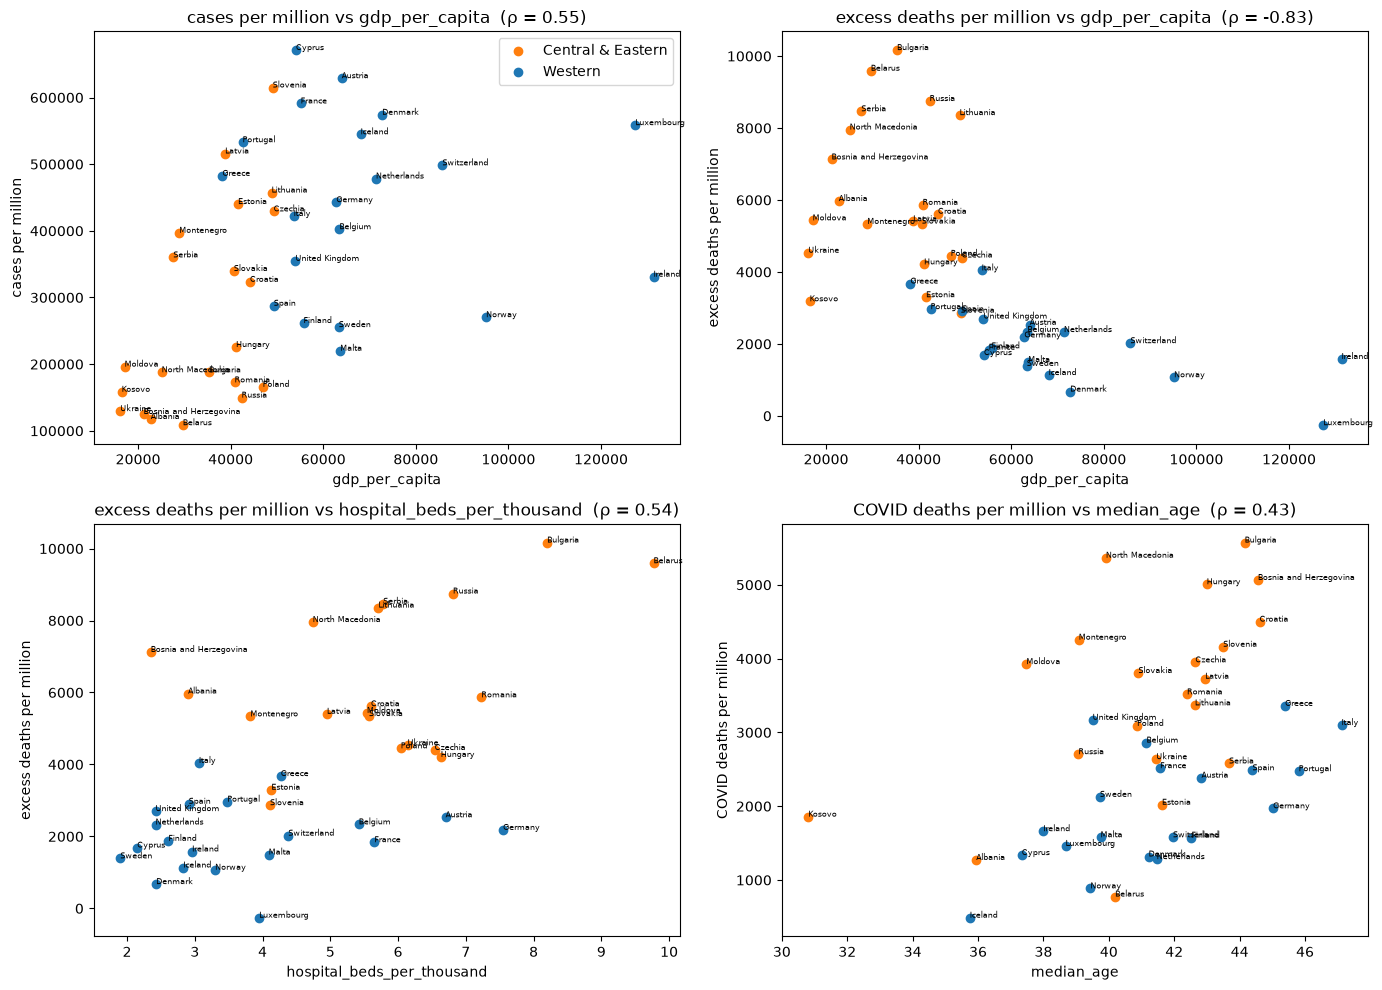

In [ ]:
region_colors = {"Western": "tab:blue", "Central & Eastern": "tab:orange"}
pairs = [("gdp_per_capita", "cases per million"),
         ("gdp_per_capita", "excess deaths per million"),
         ("hospital_beds_per_thousand", "excess deaths per million"),
         ("median_age", "COVID deaths per million")]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (x, y) in zip(axes.flat, pairs):
    for region, g in q6.groupby("region"):
        ax.scatter(g[x], g[y], color=region_colors[region], label=region)
    for country, r in q6.iterrows():
        ax.annotate(country, (r[x], r[y]), fontsize=6)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f"{y} vs {x}  (ρ = {q6[[x, y]].corr(method='spearman').iloc[0, 1]:.2f})")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

**Observations (Q6):**
* **Richer countries reported more cases but had far fewer excess deaths.** GDP per capita
  correlates *positively* with reported cases per million (ρ ≈ 0.55) and *strongly negatively* with
  excess deaths per million (ρ ≈ -0.83). Tests per thousand show the same split (ρ ≈ 0.78 with
  cases, ≈ -0.47 with excess deaths): reported cases measure testing capacity as much as infections.
* Median age (ρ ≈ 0.43) and diabetes prevalence (ρ ≈ 0.37) are associated with more COVID deaths,
  as expected.
* Two counter-intuitive results: **more hospital beds go with *more* excess deaths** (ρ ≈ 0.54) and
  **population density with *fewer*** (ρ ≈ -0.35). The scatter plots show why: Central & Eastern
  European countries combine many hospital beds (a legacy of their health systems), lower GDP and
  high excess mortality, so the correlation is driven by the East-West split rather than by the
  beds themselves (confounding). The dashboard should make this visible by colouring by region.
* Average policy stringency over 2020–2022 is practically uncorrelated with all three outcomes
  (|ρ| < 0.1).

### 6.7 Q7: how reliable are official COVID-19 death counts?

**Question:** where is the gap between reported COVID-19 deaths and excess mortality largest?

If official statistics captured all COVID-19 deaths, excess mortality and reported COVID-19 deaths
would be similar (points close to the diagonal). Points far above the diagonal suggest
under-reporting of COVID-19 deaths (or other causes of excess deaths).

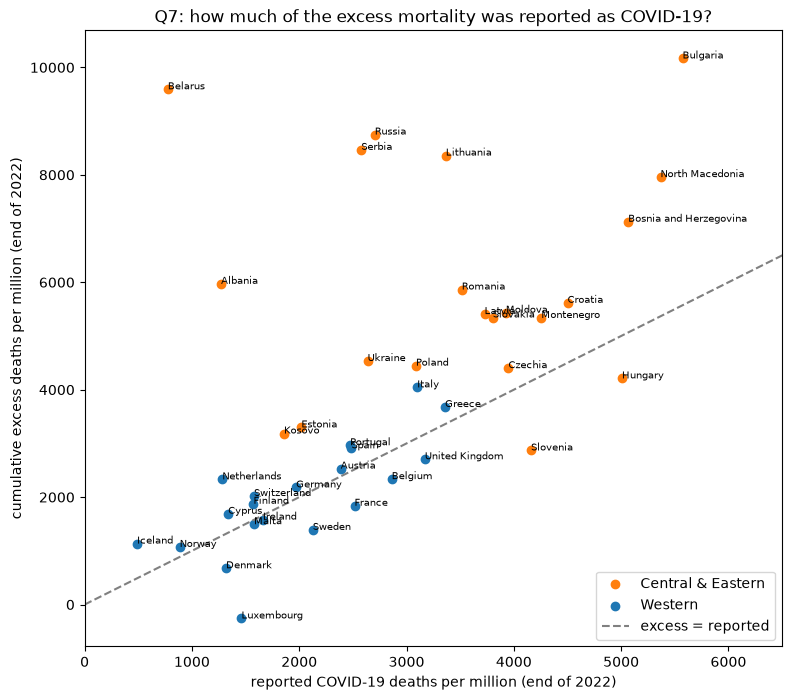

country
Belarus        12.4
Albania         4.7
Serbia          3.3
Russia          3.2
Lithuania       2.5
Iceland         2.3
Bulgaria        1.8
Netherlands     1.8
Name: excess / reported, dtype: float64

In [ ]:
fig, ax = plt.subplots(figsize=(9, 8))
for region, g in q6.groupby("region"):
    ax.scatter(g["COVID deaths per million"], g["excess deaths per million"],
               color=region_colors[region], label=region)
for country, r in q6.iterrows():
    ax.annotate(country, (r["COVID deaths per million"], r["excess deaths per million"]), fontsize=7)
ax.plot([0, 10000], [0, 10000], color="grey", linestyle="--", label="excess = reported")
ax.set_xlim(0, 6500)
ax.set_xlabel("reported COVID-19 deaths per million (end of 2022)")
ax.set_ylabel("cumulative excess deaths per million (end of 2022)")
ax.set_title("Q7: how much of the excess mortality was reported as COVID-19?")
ax.legend()
plt.show()

q6["excess / reported"] = q6["excess deaths per million"] / q6["COVID deaths per million"]
q6["excess / reported"].sort_values(ascending=False).round(1).head(8)

**Observations (Q7):** Western countries lie close to the diagonal (excess ≈ reported deaths), while
most Central & Eastern countries lie far above it. Belarus reported ~780 COVID deaths per million but
had ~9,600 excess deaths per million (12×); Albania (4.7×), Serbia (3.3×) and Russia (3.2×) follow.
This suggests large under-reporting, so comparisons based on reported deaths alone would be
misleading.

## 7. Computational analysis: first attempt for Q3 (data reduction)

Each country's policy response can be described as a time series of 36 monthly Stringency values
(2020–2022), i.e. a 36-dimensional vector. To see whether there are groups of similar strategies we
reduce these vectors to 2 dimensions with **PCA** and group them with **k-means**.

In [43]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

profiles = (eu.set_index("Date").groupby("CountryName")["StringencyIndex_Average"]
            .resample("MS").mean().unstack())
profiles = profiles.dropna()
print(profiles.shape, "(countries x months)")

pca = PCA(n_components=2)
coords = pd.DataFrame(pca.fit_transform(profiles), index=profiles.index, columns=["PC1", "PC2"])
print("explained variance:", pca.explained_variance_ratio_.round(2))

coords["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(profiles)

(38, 36) (countries x months)
explained variance: [0.4  0.17]


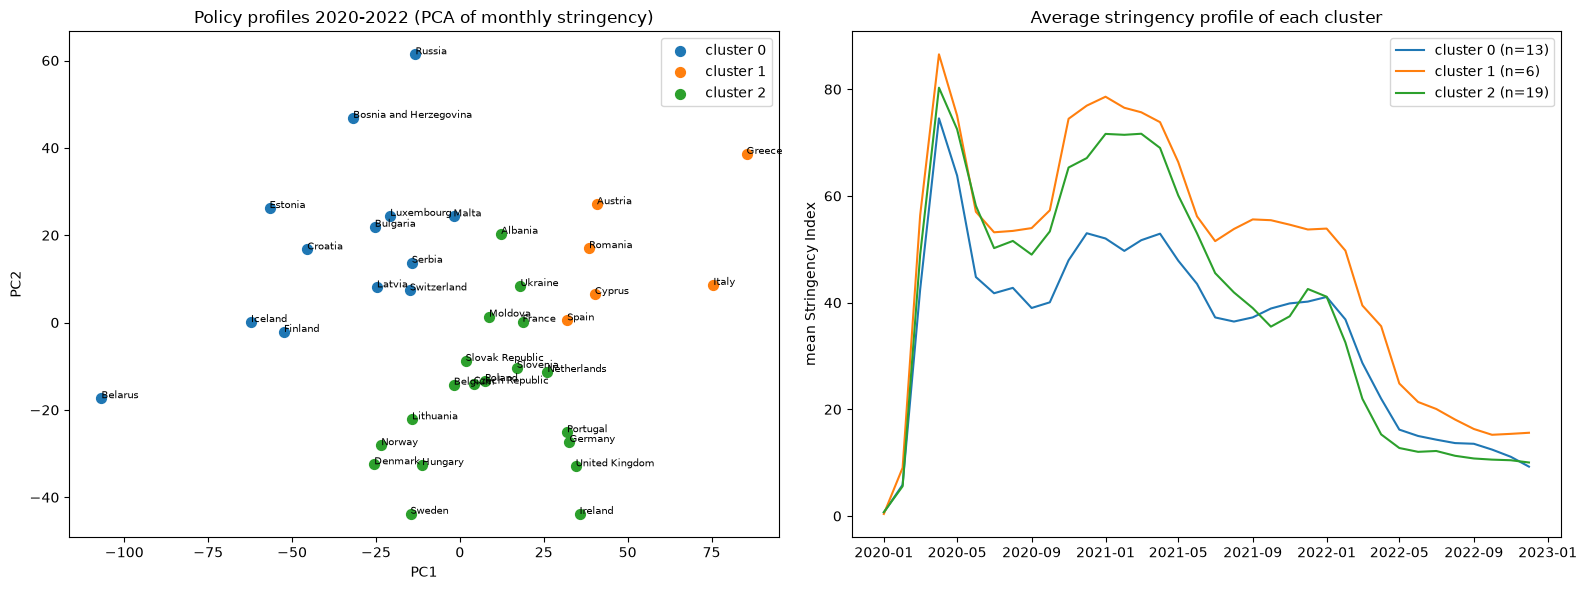

cluster 0: Belarus, Bosnia and Herzegovina, Bulgaria, Croatia, Estonia, Finland, Iceland, Latvia, Luxembourg, Malta, Russia, Serbia, Switzerland
cluster 1: Austria, Cyprus, Greece, Italy, Romania, Spain
cluster 2: Albania, Belgium, Czech Republic, Denmark, France, Germany, Hungary, Ireland, Lithuania, Moldova, Netherlands, Norway, Poland, Portugal, Slovak Republic, Slovenia, Sweden, Ukraine, United Kingdom


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for c, g in coords.groupby("cluster"):
    axes[0].scatter(g["PC1"], g["PC2"], label=f"cluster {c}", s=50)
for country, r in coords.iterrows():
    axes[0].annotate(country, (r["PC1"], r["PC2"]), fontsize=7)
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].set_title("Policy profiles 2020-2022 (PCA of monthly stringency)")
axes[0].legend()

for c in sorted(coords["cluster"].unique()):
    members = coords[coords["cluster"] == c].index
    axes[1].plot(profiles.columns, profiles.loc[members].mean(), label=f"cluster {c} (n={len(members)})")
axes[1].set_ylabel("mean Stringency Index")
axes[1].set_title("Average stringency profile of each cluster")
axes[1].legend()
plt.tight_layout()
plt.show()

for c in sorted(coords["cluster"].unique()):
    print(f"cluster {c}:", ", ".join(coords[coords["cluster"] == c].index))

Other places where data reduction / transformation is needed:
* Normalisation and alignment - relative time (days from Day 0) and per-100k rates are transformations required by Q1.
* Temporal aggregation - weekly/monthly aggregation to reconcile daily and weekly sources (Q2, Q5).
* Richer policy vectors - next step: use all containment indicators (C1-C8, H6) instead of the composite index, compare PCA with UMAP, and try hierarchical clustering (dendrogram) to choose the number of clusters.
* Country characteristics (Q6) - PCA on demographic/economic variables to summarise structural differences.